In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import chi2_contingency
from pathlib import Path

import shap
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score,
    log_loss,
    roc_auc_score,
    brier_score_loss
)
from sklearn.calibration import CalibrationDisplay

from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from xgboost import XGBClassifier, plot_importance


In [2]:
DATA_FILE = Path("dataset") / "compras_data.csv"

# Análisis Exploratorio de Datos

In [3]:
df = pd.read_csv(DATA_FILE)
df.head()

,id,dia_visita,incidencia_compra,id_marca,cantidad,ultima_marca_comprada,ultima_cantidad_comprada,precio_marca_1,precio_marca_2,precio_marca_3,...,promo_marca_3,promo_marca_4,promo_marca_5,genero,estado_civil,edad,nivel_educacion,ingreso_anual,ocupacion,tamanio_ciudad
0,200000001,1,0,0,0,0,0,1.59,1.87,2.01,...,0,0,0,0,0,47,1,110866,1,0
1,200000001,11,0,0,0,0,0,1.51,1.89,1.99,...,0,0,0,0,0,47,1,110866,1,0
2,200000001,12,0,0,0,0,0,1.51,1.89,1.99,...,0,0,0,0,0,47,1,110866,1,0
3,200000001,16,0,0,0,0,0,1.52,1.89,1.98,...,0,0,0,0,0,47,1,110866,1,0
4,200000001,18,0,0,0,0,0,1.52,1.89,1.99,...,0,0,0,0,0,47,1,110866,1,0


In [4]:
import pandas as pd

# Assuming your DataFrame is named 'df'
unique_ids = df['id'].nunique()
unique_dias = df['dia_visita'].nunique()
unique_combinations = df[['id', 'dia_visita']].drop_duplicates().shape[0]

print(f'Unique IDs: {unique_ids:,}')
print(f'Unique Dias (Days): {unique_dias:,}')
print(f'Unique (id, dia_visita) combinations: {unique_combinations:,}')
print(f'Total rows in DataFrame: {len(df):,}')

# Check if (id, dia) is a strict primary key
if unique_combinations == len(df):
  print('-> (id, dia_visita) is a unique primary key combination (no duplicates).')
else:
  print(
      '-> Duplicate (id, dia_visita) pairs exist! Difference:'
      f' {len(df) - unique_combinations:,} rows'
  )

Unique IDs: 500
Unique Dias (Days): 730
Unique (id, dia_visita) combinations: 58,693
Total rows in DataFrame: 58,693
-> (id, dia_visita) is a unique primary key combination (no duplicates).


In [5]:
df.dtypes

id                            int64
dia_visita                    int64
incidencia_compra             int64
id_marca                      int64
cantidad                      int64
ultima_marca_comprada         int64
ultima_cantidad_comprada      int64
precio_marca_1              float64
precio_marca_2              float64
precio_marca_3              float64
precio_marca_4              float64
precio_marca_5              float64
promo_marca_1                 int64
promo_marca_2                 int64
promo_marca_3                 int64
promo_marca_4                 int64
promo_marca_5                 int64
genero                        int64
estado_civil                  int64
edad                          int64
nivel_educacion               int64
ingreso_anual                 int64
ocupacion                     int64
tamanio_ciudad                int64
dtype: object

In [6]:
df.shape

(58693, 24)

In [7]:
# Target variable
target = ['incidencia_compra']

# Identifiers, keys, and leakage/confounding variables to exclude from modeling EDA
excluded_features = [
    'id',               # Customer key
    'dia_visita',       # Time index key
    'cantidad',         # Leakage: 0 if no purchase, >0 if purchased
    'id_marca',         # Leakage: Brand chosen during the visit (unknown if no purchase)
    'tamanio_ciudad'    # Ignored per instructions
]

# Numerical Predictive Features 
numerical_features = [
    'edad',
    'ingreso_anual',
    'precio_marca_1',
    'precio_marca_2',
    'precio_marca_3',
    'precio_marca_4',
    'precio_marca_5',
]

# Categorical Predictive Features 
categorical_features = [
    'ultima_cantidad_comprada',  
    'ultima_marca_comprada',   
    'promo_marca_1',            
    'promo_marca_2',
    'promo_marca_3',
    'promo_marca_4',
    'promo_marca_5',
    'genero',
    'estado_civil',
    'nivel_educacion',
    'ocupacion'
]

## Análisis univariado de variables numéricas

--- SUMMARY STATISTICS ---


,edad,ingreso_anual,precio_marca_1,precio_marca_2,precio_marca_3,precio_marca_4,precio_marca_5
count,58693.000000,58693.000000,58693.000000,58693.000000,58693.000000,58693.000000,58693.000000
mean,38.793962,121841.644319,1.392074,1.780999,2.006789,2.159945,2.654798
std,12.052447,40643.740678,0.091139,0.170868,0.046867,0.089825,0.098272
min,18.000000,38247.000000,1.100000,1.260000,1.870000,1.760000,2.110000
25%,30.000000,95541.000000,1.340000,1.580000,1.970000,2.120000,2.630000
50%,36.000000,117971.000000,1.390000,1.880000,2.010000,2.170000,2.670000
75%,46.000000,138525.000000,1.470000,1.890000,2.060000,2.240000,2.700000
max,75.000000,309364.000000,1.590000,1.900000,2.140000,2.260000,2.800000



--- MISSING VALUES ---
edad              0
ingreso_anual     0
precio_marca_1    0
precio_marca_2    0
precio_marca_3    0
precio_marca_4    0
precio_marca_5    0
dtype: int64


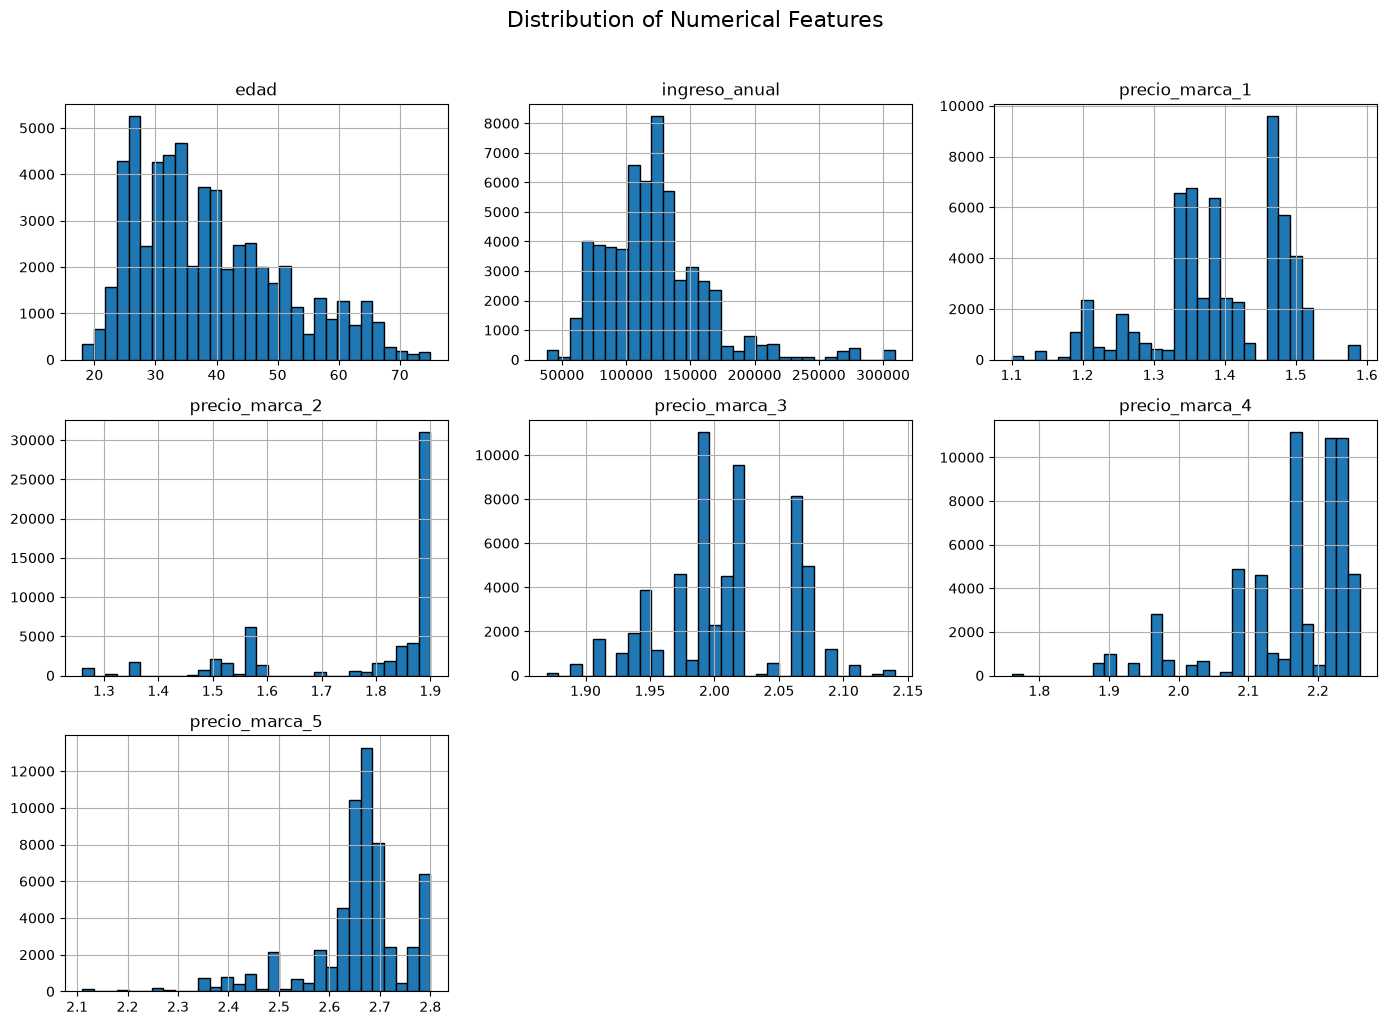

In [8]:
# 1. Summary Statistics & Missing Values Check
print('--- SUMMARY STATISTICS ---')
display(df[numerical_features].describe())

print('\n--- MISSING VALUES ---')
print(df[numerical_features].isnull().sum())

# 2. Univariate Distributions (Histograms)
df[numerical_features].hist(bins=30, figsize=(14, 10), edgecolor='black')
plt.suptitle('Distribution of Numerical Features', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

## Análisis bivariado de variables numéricas

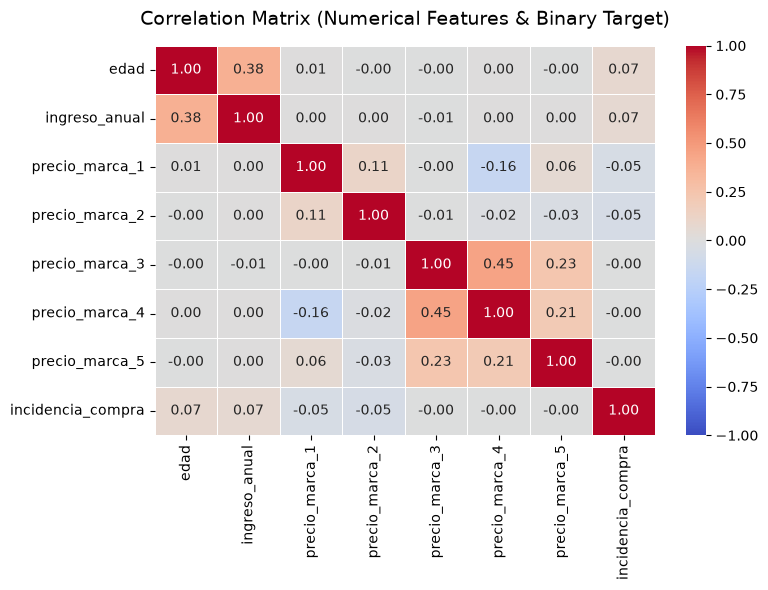

In [9]:
# Calculate correlation matrix
corr_matrix = df[numerical_features + target].corr()

# Plot the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)
plt.title(
    'Correlation Matrix (Numerical Features & Binary Target)',
    fontsize=14,
    pad=15,
)
plt.tight_layout()
plt.show()

## Análisis univariado de variables categóricas 

In [10]:
for col in categorical_features:
  print(f'--- {col} ---')
  print(df[col].value_counts(normalize=True) * 100)
  print('\n')

print('\n--- MISSING VALUES ---')
print(df[categorical_features].isnull().sum())

--- ultima_cantidad_comprada ---
ultima_cantidad_comprada
0    75.192953
1    24.807047
Name: proportion, dtype: float64


--- ultima_marca_comprada ---
ultima_marca_comprada
0    75.192953
5     8.471198
2     7.651679
4     4.964817
1     2.298400
3     1.420953
Name: proportion, dtype: float64


--- promo_marca_1 ---
promo_marca_1
0    65.616002
1    34.383998
Name: proportion, dtype: float64


--- promo_marca_2 ---
promo_marca_2
0    68.439167
1    31.560833
Name: proportion, dtype: float64


--- promo_marca_3 ---
promo_marca_3
0    95.720103
1     4.279897
Name: proportion, dtype: float64


--- promo_marca_4 ---
promo_marca_4
0    88.214949
1    11.785051
Name: proportion, dtype: float64


--- promo_marca_5 ---
promo_marca_5
0    96.413542
1     3.586458
Name: proportion, dtype: float64


--- genero ---
genero
0    61.411071
1    38.588929
Name: proportion, dtype: float64


--- estado_civil ---
estado_civil
0    60.688668
1    39.311332
Name: proportion, dtype: float64


--- nivel

## Análisis bivariado de variables categóricas

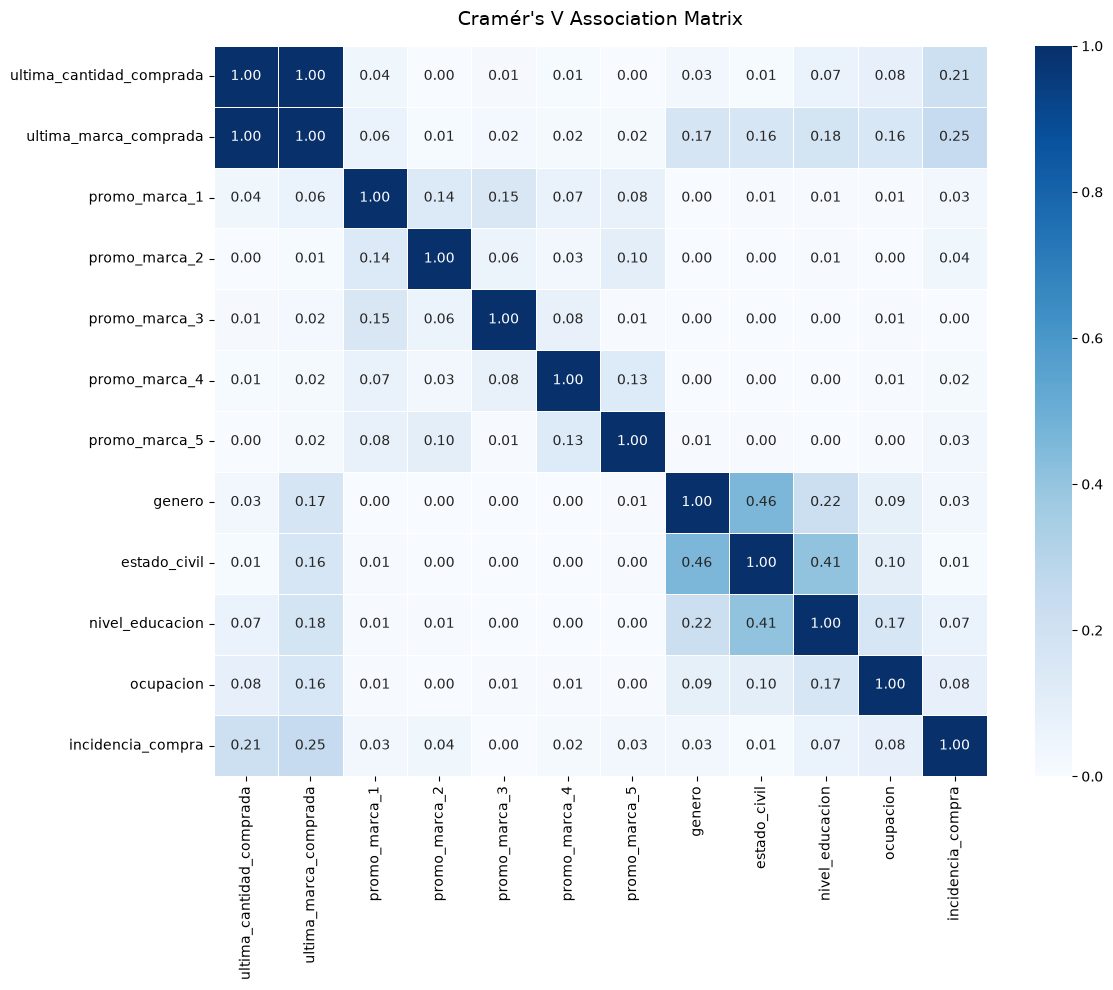

In [11]:
def cramers_v_calc(confusion_matrix):
  # confusion_matrix can be a pandas crosstab converted to numpy
  dataset = confusion_matrix.to_numpy()
  X2 = chi2_contingency(dataset, correction=False)[0]
  N = np.sum(dataset)
  min_dim = min(dataset.shape) - 1

  if min_dim == 0 or N == 0:
    return 0.0

  return np.sqrt((X2 / N) / min_dim)


# Build the matrix quickly using your categorical features + target
target_col = target[0] if isinstance(target, list) else target
all_cats = categorical_features + [target_col]

corr_df = pd.DataFrame(index=all_cats, columns=all_cats, dtype=float)

for col1 in all_cats:
  for col2 in all_cats:
    if col1 == col2:
      corr_df.loc[col1, col2] = 1.0
    else:
      obs = pd.crosstab(df[col1], df[col2])
      corr_df.loc[col1, col2] = cramers_v_calc(obs)


plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_df,
    annot=True,
    fmt='.2f',
    cmap='Blues',
    vmin=0,
    vmax=1,
    linewidths=0.5,
)
plt.title("Cramér's V Association Matrix", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

## Variance Inflator Factor

In [12]:
def compute_vif(dataframe):
  
  active_num = [f for f in numerical_features if f in dataframe.columns]
  active_cat = [f for f in categorical_features if f in dataframe.columns]

  df_cats_str = dataframe[active_cat].astype(str)

  X_encoded = pd.concat(
      [dataframe[active_num], pd.get_dummies(df_cats_str, drop_first=True)],
      axis=1,
  ).astype(float)

  vif_df = pd.DataFrame({
      'Feature': X_encoded.columns,
      'VIF': [
          variance_inflation_factor(X_encoded.values, i)
          for i in range(X_encoded.shape[1])
      ],
  }).sort_values(by='VIF', ascending=False).reset_index(drop=True)

  return vif_df

In [13]:
display(compute_vif(df).head(10))

C:\Users\IRVIN\AppData\Local\Temp\ipykernel_12000\3205460037.py:16: UserWarning: The design matrix is poorly conditioned (condition number=1.24e+15). VIF calculations may be numerically unstable.
  variance_inflation_factor(X_encoded.values, i)
c:\Users\IRVIN\Proyectos\Pruebas laborales\Ferreycorp\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\IRVIN\Proyectos\Pruebas laborales\Ferreycorp\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\Users\IRVIN\Proyectos\Pruebas laborales\Ferreycorp\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are

,Feature,VIF
0,ultima_cantidad_comprada_1,1.000800e+15
1,ultima_marca_comprada_1,1.000800e+15
2,ultima_marca_comprada_4,1.000800e+15
3,ultima_marca_comprada_3,1.000800e+15
4,ultima_marca_comprada_2,1.000800e+15
5,ultima_marca_comprada_5,1.000800e+15
6,nivel_educacion_2,6.596469e+00
7,edad,3.455224e+00
8,nivel_educacion_1,3.000008e+00
9,ocupacion_2,2.505361e+00


In [14]:
display(compute_vif(df.drop(columns=['ultima_cantidad_comprada'])).head(10))

,Feature,VIF
0,nivel_educacion_2,6.596469
1,edad,3.455224
2,nivel_educacion_1,3.000008
3,ocupacion_2,2.505361
4,ingreso_anual,2.451234
5,estado_civil_1,2.025580
6,nivel_educacion_3,1.886184
7,precio_marca_4,1.820102
8,ocupacion_1,1.677560
9,precio_marca_3,1.415114


# Metodología

# Procesamiento y limpieza de datos

## Feature Engineering

Features a crear:
Recency:
Days since last visit
Days since last purchase
Visit frequency in the last 30 days
Visit frequency in the last 90 days

Conversion:
conversion rate of customer in the last 30 days
conversion rate of customer in the last 90 days

Pricing:
average price today/ rolling average price 30 days
average price today/ last paid price
max - min price gap
purchasing power income/average price

brand royalty:
historical share of purchases per brand
brand x promo, whether the last purchased brand is on promotion today
last brand price change against today

In [37]:
df = df.sort_values(["id", "dia_visita"]).reset_index(drop=True)

price_cols = [f"precio_marca_{i}" for i in range(1, 6)]

df["average_price_today"] = df[price_cols].mean(axis=1)

purch = df["incidencia_compra"].astype(bool)

def last_before_today(s):
    last_purch_val = (
        s.where(purch)
         .groupby(df["id"], sort=False)
         .ffill()
    )
    return last_purch_val.groupby(df["id"], sort=False).shift(1)

# --------------------------------------------------
# 1. RECENCY
# --------------------------------------------------

df["days_since_last_visit"] = (
    df["dia_visita"] - df.groupby("id")["dia_visita"].shift(1)
)

df["last_purchase_day"] = last_before_today(df["dia_visita"])
df["days_since_last_purchase"] = df["dia_visita"] - df["last_purchase_day"]



# --------------------------------------------------
# 2. CALENDAR-DAY ROLLING WINDOWS
# --------------------------------------------------

df["visit_frequency_30d"] = 0.0
df["visit_frequency_90d"] = 0.0
df["conversion_rate_30d"] = np.nan
df["conversion_rate_90d"] = np.nan
df["rolling_average_price_30d"] = np.nan

for _, g in df.groupby("id", sort=False):

    idx = g.index
    dates = pd.to_timedelta(g["dia_visita"], unit="D")

    visits = pd.Series(1.0, index=dates)

    purchases = pd.Series(
        g["incidencia_compra"].astype(float).to_numpy(),
        index=dates
    )

    prices = pd.Series(
        g["average_price_today"].to_numpy(),
        index=dates
    )

    for window in ["30D", "90D"]:

        visit_count = visits.rolling(
            window, closed="left"
        ).sum()

        purchase_count = purchases.rolling(
            window, closed="left"
        ).sum()

        df.loc[idx, f"visit_frequency_{window.lower()}"] = (
            visit_count.fillna(0).to_numpy()
        )

        df.loc[idx, f"conversion_rate_{window.lower()}"] = (
            purchase_count / visit_count
        ).to_numpy()

    df.loc[idx, "rolling_average_price_30d"] = (
        prices.rolling("30D", closed="right").mean().to_numpy()
    )


# --------------------------------------------------
# 3. PRICING
# --------------------------------------------------
df["last_paid_avg_price"] = last_before_today(df["average_price_today"])
df["price_vs_last_paid"] = df["average_price_today"] / df["last_paid_avg_price"]

df["last_paid_brand"] = last_before_today(df["id_marca"])

# helper only: price of the brand bought on a purchase row
df["_price_of_purchased_brand"] = np.nan
for i in range(1, 6):
    mask = purch & df["id_marca"].eq(i)
    df.loc[mask, "_price_of_purchased_brand"] = df.loc[mask, f"precio_marca_{i}"]

df["last_paid_price"] = last_before_today(df["_price_of_purchased_brand"])
df["average_price_today_vs_last_paid"] = (
    df["average_price_today"] / df["last_paid_price"]
)

df["max_min_price_gap"] = df[price_cols].max(axis=1) - df[price_cols].min(axis=1)
df["purchasing_power"] = df["ingreso_anual"] / df["average_price_today"]

df = df.drop(columns=["_price_of_purchased_brand"])

# --------------------------------------------------
# 4. BRAND ROYALTY
# --------------------------------------------------

df["total_historical_purchases"] = (
    df["cantidad"]
    .where(df["incidencia_compra"].eq(1), 0)
    .groupby(df["id"])
    .transform(lambda x: x.cumsum().shift(1, fill_value=0))
)

for i in range(1, 6):

    brand_quantity = df["cantidad"].where(
        df["incidencia_compra"].eq(1) &
        df["id_marca"].eq(i),
        0
    )

    df[f"brand_{i}_historical_purchases"] = (
        brand_quantity
        .groupby(df["id"])
        .transform(lambda x: x.cumsum().shift(1, fill_value=0))
    )

    df[f"brand_{i}_historical_share"] = (
        df[f"brand_{i}_historical_purchases"] /
        df["total_historical_purchases"].replace(0, np.nan)
    )


# --------------------------------------------------
# 5. LAST PURCHASED BRAND PROMOTION TODAY
# --------------------------------------------------

df["last_brand_promo_today"] = np.nan
df["current_last_brand_price"] = np.nan
for i in range(1, 6):
    mask = df["last_paid_brand"].eq(i)
    df.loc[mask, "last_brand_promo_today"] = df.loc[mask, f"promo_marca_{i}"]
    df.loc[mask, "current_last_brand_price"] = df.loc[mask, f"precio_marca_{i}"]

# --------------------------------------------------
# 6. LAST PAID PRICE VS CURRENT SAME-BRAND PRICE
# --------------------------------------------------

df["last_paid_price_vs_current_same_brand"] = (
    df["last_paid_price"] /
    df["current_last_brand_price"]
)

df["last_brand_price_change_pct"] = (
    df["current_last_brand_price"] /
    df["last_paid_price"] - 1
)


## Train - test splitting

In [17]:
# Engineered Numerical Features
active_features_numerical = numerical_features + [
    # Recency
    'days_since_last_visit',
    'days_since_last_purchase',
    'visit_frequency_30d',
    'visit_frequency_90d',

    # Conversion
    'conversion_rate_30d',
    'conversion_rate_90d',

    # Pricing
    'average_price_today',
    'rolling_average_price_30d',
    'average_price_today_vs_last_paid',
    'max_min_price_gap',
    'purchasing_power',
    'last_paid_price',
    'current_last_brand_price',
    'last_paid_price_vs_current_same_brand',
    'last_brand_price_change_pct',

    # Brand royalty
    'total_historical_purchases',
    'brand_1_historical_purchases',
    'brand_2_historical_purchases',
    'brand_3_historical_purchases',
    'brand_4_historical_purchases',
    'brand_5_historical_purchases',

    'brand_1_historical_share',
    'brand_2_historical_share',
    'brand_3_historical_share',
    'brand_4_historical_share',
    'brand_5_historical_share',
]


# Engineered Categorical Features
active_features_categorical = categorical_features + [
    # Brand royalty / promotions
    'last_brand_promo_today',
]

active_features_categorical = [
    col for col in categorical_features
    if col != 'ultima_cantidad_comprada'
]

# Final predictive feature list
active_features = (
    active_features_numerical +
    active_features_categorical
)

# --- CHRONOLOGICAL SPLIT ---
df_sorted = df.sort_values('dia_visita').reset_index(drop=True)

X = df_sorted[active_features]
y = df_sorted[target[0]]

split_idx = int(len(df) * 0.8)

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

# Quick verification of shapes and class distributions
print(f'Train shape: {X_train.shape}, Test shape: {X_test.shape}')
print(f'Train target distribution:\n{y_train.value_counts(normalize=True)}')
print(f'Test target distribution:\n{y_test.value_counts(normalize=True)}')

Train shape: (46954, 43), Test shape: (11739, 43)
Train target distribution:
incidencia_compra
0    0.751523
1    0.248477
Name: proportion, dtype: float64
Test target distribution:
incidencia_compra
0    0.746912
1    0.253088
Name: proportion, dtype: float64


In [18]:
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])


preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, active_features_numerical),
        ('cat', categorical_transformer, active_features_categorical),
    ]
)

# Desarrollo de modelo de propensión de compra

## Evaluador de ajuste del modelo

In [24]:
def evaluate_model(pipeline, X, y, model_name='Model',
                   plot_probabilities=False,
                   plot_calibration=False):

    # Predict probabilities for the positive class (1)
    y_pred_proba = pipeline.predict_proba(X)[:, 1]

    # Evaluation metrics
    metrics = {
        'ROC-AUC': roc_auc_score(y, y_pred_proba),
        'PR-AUC': average_precision_score(y, y_pred_proba),
        'Log Loss': log_loss(y, y_pred_proba, labels=[0, 1]),
        'Brier Score': brier_score_loss(y, y_pred_proba)
    }

    print(f'=== Evaluation Results: {model_name} ===')

    for metric_name, val in metrics.items():
        print(f'{metric_name}: {val:.4f}')

    # 1. Probability distribution by actual class (KDE)
    if plot_probabilities:
        plt.figure(figsize=(4, 3))

        sns.kdeplot(
            x=y_pred_proba,
            hue=y,
            hue_order=[0, 1],
            common_norm=False,
            fill=True,
            palette={0: 'salmon', 1: 'skyblue'}
        )

        plt.title('Probability Distribution by Class')
        plt.xlabel('Predicted Probability of Purchase')
        plt.ylabel('Density')
        plt.show()

    # 2. Calibration curve
    if plot_calibration:
        fig, ax = plt.subplots(figsize=(4, 3))

        CalibrationDisplay.from_predictions(
            y,
            y_pred_proba,
            n_bins=10,
            strategy='quantile',
            name=model_name,
            ax=ax
        )

        ax.set_title(f'Calibration Curve: {model_name}')
        plt.tight_layout()
        plt.show()

    return metrics, y_pred_proba


## Models fitting


--- Training LogisticRegression ---
=== Evaluation Results: LogisticRegression (Train) ===
ROC-AUC: 0.7436
PR-AUC: 0.5511
Log Loss: 0.4778
Brier Score: 0.1535
--- Testing LogisticRegression ---
=== Evaluation Results: LogisticRegression (Test) ===
ROC-AUC: 0.7118
PR-AUC: 0.5006
Log Loss: 0.5073
Brier Score: 0.1645


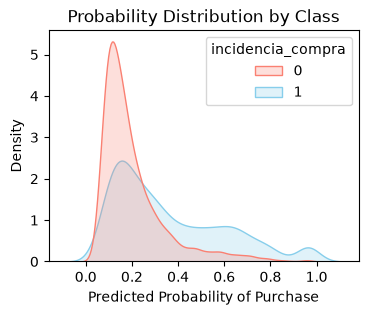

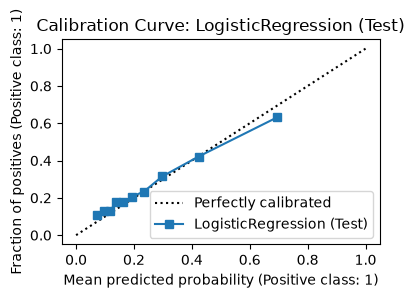


--- Training RandomForest ---
=== Evaluation Results: RandomForest (Train) ===
ROC-AUC: 0.7635
PR-AUC: 0.5860
Log Loss: 0.4686
Brier Score: 0.1498
--- Testing RandomForest ---
=== Evaluation Results: RandomForest (Test) ===
ROC-AUC: 0.7150
PR-AUC: 0.5017
Log Loss: 0.5040
Brier Score: 0.1641


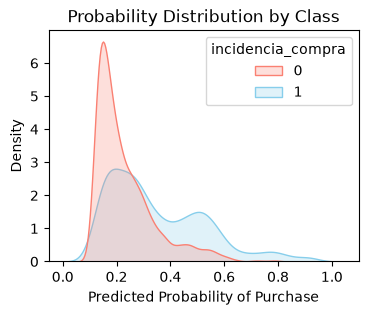

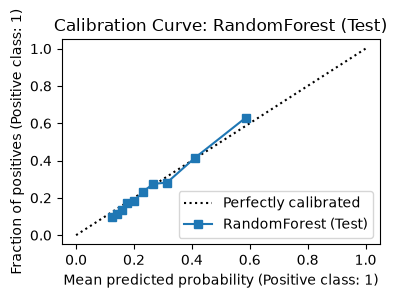


--- Training XGBoost ---
=== Evaluation Results: XGBoost (Train) ===
ROC-AUC: 0.7837
PR-AUC: 0.6099
Log Loss: 0.4522
Brier Score: 0.1442
--- Testing XGBoost ---
=== Evaluation Results: XGBoost (Test) ===
ROC-AUC: 0.7263
PR-AUC: 0.5084
Log Loss: 0.5009
Brier Score: 0.1631


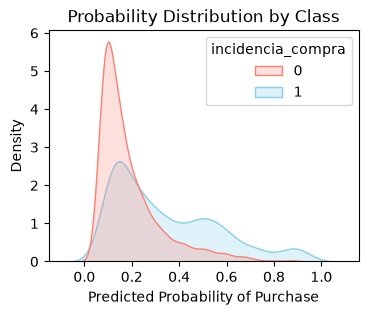

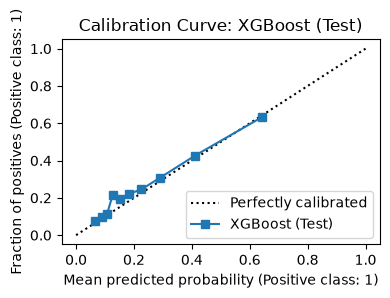


--- Training LightGBM ---
=== Evaluation Results: LightGBM (Train) ===
ROC-AUC: 0.7841
PR-AUC: 0.6109
Log Loss: 0.4519
Brier Score: 0.1441
--- Testing LightGBM ---
=== Evaluation Results: LightGBM (Test) ===
ROC-AUC: 0.7273
PR-AUC: 0.5039
Log Loss: 0.4999
Brier Score: 0.1632


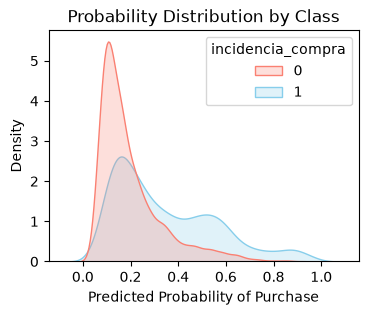

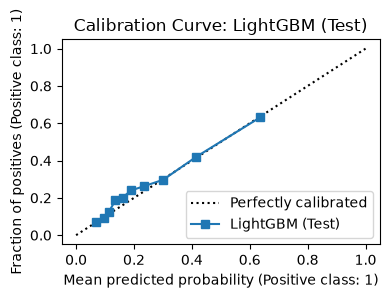


--- Training HistGradientBoosting ---
=== Evaluation Results: HistGradientBoosting (Train) ===
ROC-AUC: 0.7842
PR-AUC: 0.6097
Log Loss: 0.4520
Brier Score: 0.1442
--- Testing HistGradientBoosting ---
=== Evaluation Results: HistGradientBoosting (Test) ===
ROC-AUC: 0.7268
PR-AUC: 0.5032
Log Loss: 0.5005
Brier Score: 0.1633


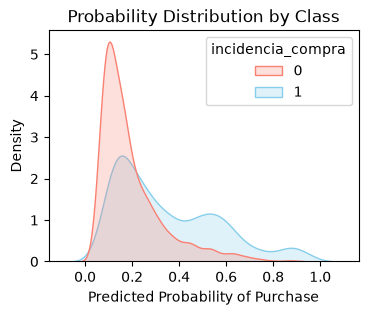

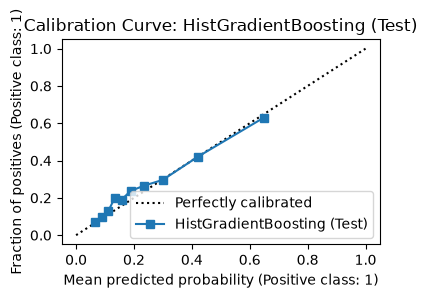

In [25]:
# 1. Comprehensive Model Suite
model_suite = {
    'LogisticRegression': LogisticRegression(max_iter=1000, random_state=42),
    'RandomForest': RandomForestClassifier(
        n_estimators=100, max_depth=6, random_state=16, n_jobs=-1
    ),
    'XGBoost': XGBClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=4,
        random_state=16,
        eval_metric='logloss',
        n_jobs=-1,
    ),
    'LightGBM': LGBMClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=4,
        random_state=16,
        n_jobs=-1,
        verbose=-1,
    ),
    'HistGradientBoosting': HistGradientBoostingClassifier(
        max_iter=100, learning_rate=0.05, max_depth=4, random_state=42
    )
}

# 2. Train and evaluate all models in a loop
results = {}

for name, model in model_suite.items():
  pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', model)])
  pipeline.fit(X_train, y_train)

  print(f'\n--- Training {name} ---')
  train_metrics, _ = evaluate_model(pipeline, X_train, y_train, f'{name} (Train)')

  print(f'--- Testing {name} ---')
  test_metrics, test_probs = evaluate_model(pipeline, X_test, y_test, f'{name} (Test)', plot_probabilities=True, plot_calibration=True)

  # Store pipeline and metrics for later
  results[name] = {'pipeline': pipeline, 'test_metrics': test_metrics}

In [23]:
# Extract test metrics from the results dictionary
comparison_data = {}
for name, data in results.items():
  comparison_data[name] = data['test_metrics']

# Convert to DataFrame and sort by PR-AUC descending
results_df = pd.DataFrame(comparison_data).T
results_df = results_df.sort_values(by='PR-AUC', ascending=False)

print('\n=== Model Suite Test Performance Comparison ===')
print(results_df.to_string())


=== Model Suite Test Performance Comparison ===
                       ROC-AUC    PR-AUC  Log Loss  Brier Score
XGBoost               0.726320  0.508401  0.500887     0.163137
LightGBM              0.727300  0.503858  0.499933     0.163165
HistGradientBoosting  0.726804  0.503180  0.500533     0.163291
RandomForest          0.715024  0.501702  0.504007     0.164109
LogisticRegression    0.711767  0.500605  0.507315     0.164542


# Evaluación del impacto en el negocio y captura de valor

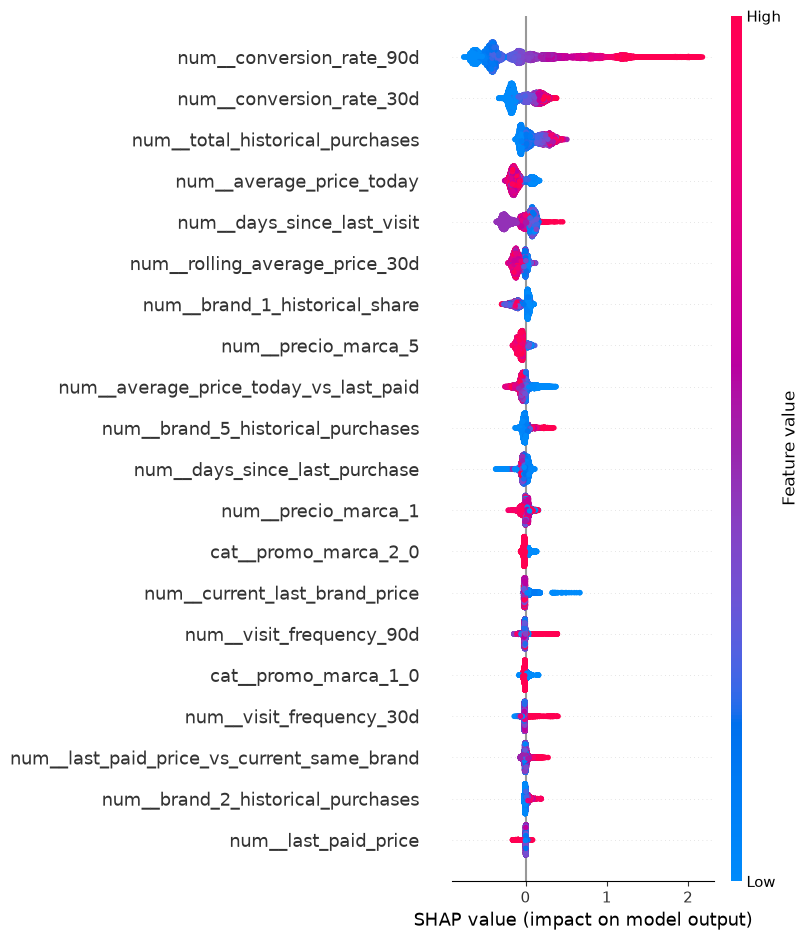

In [26]:

model = results['XGBoost']['pipeline']['classifier']
preprocessor = results['XGBoost']['pipeline']['preprocessor']

X_test_transformed = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test_transformed)

plt.figure(figsize=(10, 8))
shap.summary_plot(
    shap_values.values, X_test_transformed, feature_names=feature_names
)

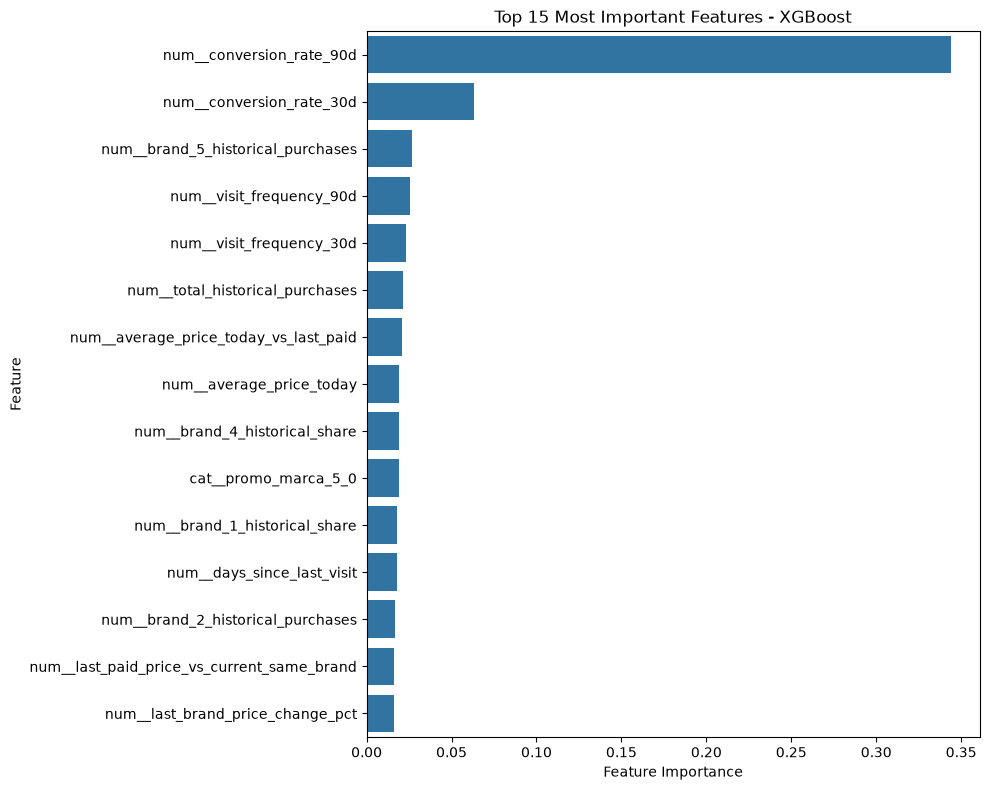

In [30]:
xgb_model = results['XGBoost']['pipeline']
xgb_classifier = xgb_model.named_steps['classifier']

importance = pd.DataFrame({
    'feature': xgb_model.named_steps['preprocessor'].get_feature_names_out(),
    'importance': xgb_classifier.feature_importances_
})

importance = importance.sort_values('importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(
    data=importance.head(15),
    x='importance',
    y='feature'
)
plt.title('Top 15 Most Important Features - XGBoost')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [32]:
propensity_results = X_test.copy()

propensity_results['actual_purchase'] = y_test.values

propensity_results['purchase_probability'] = (
    xgb_model.predict_proba(X_test)[:, 1]
)

propensity_results['propensity_segment'] = pd.cut(
    propensity_results['purchase_probability'],
    bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0],
    labels=['Very Low', 'Low', 'Medium', 'High', 'Very High'],
    include_lowest=True
)

propensity_summary = propensity_results.groupby(
    'propensity_segment',
    observed=True
).agg(
    observations=('actual_purchase', 'count'),
    average_probability=('purchase_probability', 'mean'),
    actual_purchase_rate=('actual_purchase', 'mean')
)

propensity_summary['lift'] = (
    propensity_summary['actual_purchase_rate'] / y_test.mean()
)

print(propensity_summary)

                    observations  average_probability  actual_purchase_rate  \
propensity_segment                                                            
Very Low                    7007             0.119908              0.152704   
Low                         2914             0.276953              0.293754   
Medium                      1219             0.493742              0.519278   
High                         416             0.672305              0.617788   
Very High                    183             0.881297              0.846995   

                        lift  
propensity_segment            
Very Low            0.603365  
Low                 1.160680  
Medium              2.051769  
High                2.441003  
Very High           3.346640  


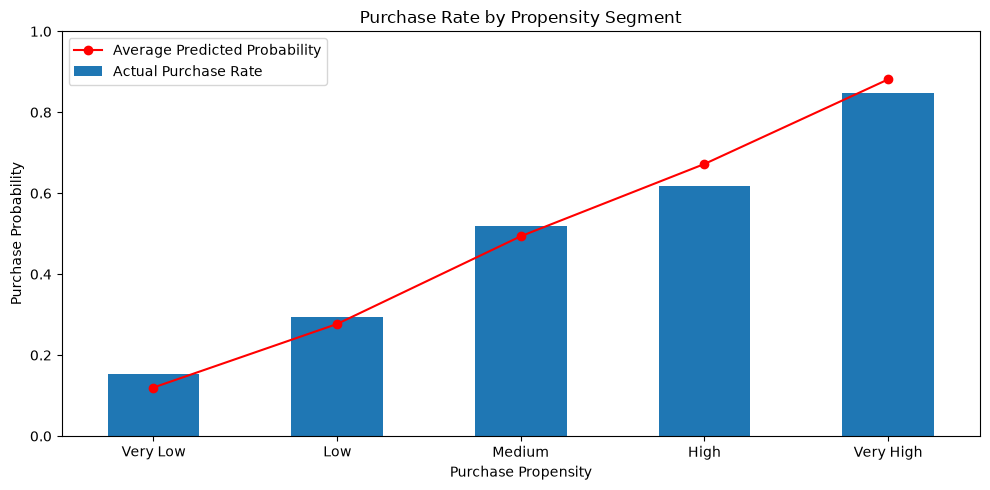

In [33]:
fig, ax = plt.subplots(figsize=(10, 5))

propensity_summary['actual_purchase_rate'].plot(
    kind='bar',
    ax=ax,
    label='Actual Purchase Rate'
)

propensity_summary['average_probability'].plot(
    kind='line',
    ax=ax,
    marker='o',
    color='red',
    label='Average Predicted Probability'
)

ax.set_title('Purchase Rate by Propensity Segment')
ax.set_xlabel('Purchase Propensity')
ax.set_ylabel('Purchase Probability')
ax.set_ylim(0, 1)

ax.legend()
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [35]:

# --------------------------------------------------
# 1. Prepare test-set results
# --------------------------------------------------

counterfactual_df = X_test.copy()

counterfactual_df['actual_purchase'] = y_test.values

# Predicted purchase probabilities from the trained XGBoost pipeline
counterfactual_df['purchase_probability'] = (
    results['XGBoost']['pipeline'].predict_proba(X_test)[:, 1]
)

# Recover actual transaction outcomes from the original dataframe
test_indices = X_test.index

counterfactual_df['quantity'] = (
    df.loc[test_indices, 'cantidad'].values
)

counterfactual_df['purchased_brand'] = (
    df.loc[test_indices, 'id_marca'].values
)

# Map each brand ID to its corresponding price column
brand_price_columns = {
    1: 'precio_marca_1',
    2: 'precio_marca_2',
    3: 'precio_marca_3',
    4: 'precio_marca_4',
    5: 'precio_marca_5'
}

# Retrieve the unit price of the brand actually purchased
counterfactual_df['purchase_price'] = np.nan

for brand_id, price_column in brand_price_columns.items():

    mask = counterfactual_df['purchased_brand'] == brand_id

    counterfactual_df.loc[mask, 'purchase_price'] = (
        df.loc[test_indices[mask], price_column].values
    )

# Calculate actual revenue:
# Revenue = Unit price × Quantity purchased
counterfactual_df['actual_revenue'] = (
    counterfactual_df['purchase_price'] *
    counterfactual_df['quantity']
).fillna(0)


# --------------------------------------------------
# 2. Define targeting capacity
# --------------------------------------------------

targeting_percentage = 0.20

n_targeted = int(
    len(counterfactual_df) * targeting_percentage
)


# --------------------------------------------------
# 3. Model-based targeting
# --------------------------------------------------

# Select the observations with the highest predicted
# purchase probabilities
model_targeted = counterfactual_df.nlargest(
    n_targeted,
    'purchase_probability'
)


# --------------------------------------------------
# 4. Random targeting simulation
# --------------------------------------------------

n_simulations = 1000

random_revenues = []
random_purchases = []

for seed in range(n_simulations):

    random_targeted = counterfactual_df.sample(
        n=n_targeted,
        random_state=seed
    )

    random_revenues.append(
        random_targeted['actual_revenue'].sum()
    )

    random_purchases.append(
        random_targeted['actual_purchase'].sum()
    )


# --------------------------------------------------
# 5. Calculate results
# --------------------------------------------------

model_revenue = model_targeted['actual_revenue'].sum()

model_purchases = model_targeted['actual_purchase'].sum()

average_random_revenue = np.mean(random_revenues)

average_random_purchases = np.mean(random_purchases)

results_comparison = pd.DataFrame({

    'Strategy': [
        'Random targeting',
        'Model-based targeting'
    ],

    'Customers targeted': [
        n_targeted,
        n_targeted
    ],

    'Actual purchases': [
        average_random_purchases,
        model_purchases
    ],

    'Purchase rate': [
        average_random_purchases / n_targeted,
        model_purchases / n_targeted
    ],

    'Revenue': [
        average_random_revenue,
        model_revenue
    ]
})


# --------------------------------------------------
# 6. Display comparison
# --------------------------------------------------

print("COUNTERFACTUAL TARGETING COMPARISON")

display(results_comparison)


# --------------------------------------------------
# 7. Estimate potential improvement
# --------------------------------------------------

revenue_difference = (
    model_revenue - average_random_revenue
)

revenue_improvement_pct = (
    (model_revenue / average_random_revenue) - 1
) * 100

purchase_difference = (
    model_purchases - average_random_purchases
)

print(f"Revenue difference: {revenue_difference:,.2f}")

print(f"Revenue improvement: {revenue_improvement_pct:.2f}%")

print(f"Additional purchases: {purchase_difference:.2f}")


# --------------------------------------------------
# 8. Quantify uncertainty in random targeting
# --------------------------------------------------

random_revenue_ci = np.percentile(
    random_revenues,
    [2.5, 97.5]
)

print(
    f"Random targeting revenue (95% simulation interval): "
    f"{random_revenue_ci[0]:,.2f} - {random_revenue_ci[1]:,.2f}"
)


# --------------------------------------------------
# 9. Revenue and purchase validation
# --------------------------------------------------

print("\nREVENUE VALIDATION")

print(
    f"Total test-set revenue: "
    f"{counterfactual_df['actual_revenue'].sum():,.2f}"
)

print(
    f"Total test-set purchases: "
    f"{counterfactual_df['actual_purchase'].sum():,.0f}"
)

print(
    f"Total test-set quantity: "
    f"{counterfactual_df['quantity'].sum():,.0f}"
)

print(
    f"Average revenue per purchase: "
    f"{counterfactual_df.loc[counterfactual_df['actual_purchase'] == 1, 'actual_revenue'].mean():,.2f}"
)


COUNTERFACTUAL TARGETING COMPARISON


,Strategy,Customers targeted,Actual purchases,Purchase rate,Revenue
0,Random targeting,2347,593.276,0.252781,4204.41704
1,Model-based targeting,2347,1243.000,0.529612,4228.89000


Revenue difference: 24.47
Revenue improvement: 0.58%
Additional purchases: 649.72
Random targeting revenue (95% simulation interval): 3,902.26 - 4,505.81

REVENUE VALIDATION
Total test-set revenue: 21,017.05
Total test-set purchases: 2,971
Total test-set quantity: 10,841
Average revenue per purchase: 1.84


# Conclusiones y limitaciones

## Conclusiones

Se desarrolló un modelo de propensión de compra utilizando técnicas de aprendizaje automático, con el objetivo de estimar la probabilidad de que un cliente realice una compra durante una visita.

Se evaluaron cinco algoritmos de clasificación: Regresión Logística, Random Forest, XGBoost, LightGBM y HistGradientBoosting. Se seleccionó **XGBoost** como modelo final debido a que obtuvo el mejor resultado en PR-AUC (0.5084), manteniendo un desempeño competitivo en las demás métricas:

- ROC-AUC: 0.7263
- PR-AUC: 0.5084
- Log Loss: 0.5009
- Brier Score: 0.1631

El análisis de propensión permitió segmentar las observaciones en cinco niveles según la probabilidad estimada de compra. Los resultados mostraron una relación positiva entre la propensión predicha y la incidencia de compra observada. En particular, el segmento de propensión muy alta alcanzó una tasa de compra del 84.70%, equivalente a un lift de 3.35 respecto a la tasa de compra general del conjunto de prueba.

Asimismo, el análisis de importancia de variables y SHAP permitió explorar los principales factores asociados a las predicciones del modelo, aportando interpretabilidad a los resultados.

En conjunto, la solución demuestra potencial para apoyar la priorización comercial, la identificación de clientes con mayor propensión de compra y el diseño de estrategias de marketing más focalizadas.

## Limitaciones

- El modelo presenta una capacidad de discriminación moderada, por lo que existe superposición entre las observaciones de compra y no compra.
- Las variables disponibles no necesariamente capturan todos los factores que influyen en la decisión de compra.
- La interpretación de las cinco marcas presentes en el dataset requiere validación con el área de negocio.
- Los resultados deben validarse con observaciones de periodos futuros antes de implementar el modelo en un entorno productivo.
- El impacto económico de las estrategias basadas en las predicciones todavía no ha sido medido mediante experimentos comerciales controlados.

## Trabajo futuro

- Incorporar nuevas variables transaccionales y de comportamiento del cliente.
- Mejorar fuerza discriminatoria del modelo.
- Definir criterios de priorización de clientes según la capacidad operativa del equipo comercial.
- Implementar campañas piloto y medir su impacto incremental en conversión e ingresos.